IMPORTING LIBRARIES

In [2]:
import numpy as numpy
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

LOADING DATASET

In [3]:
df=pd.read_csv("../data/raw/housing.csv")

DATASET INFORMATION

In [5]:
print("dataset shape:", df.shape)
print("\ndataset information")
df.info()
print("\nmissing value")
print(df.isnull().sum())

dataset shape: (20640, 10)

dataset information
<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.7 MB

missing value
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income        

STATISTICAL ANALYSIS

In [6]:
df.describe

<bound method DataFrame.describe of        longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0        -122.23     37.88                41.0        880.0           129.0   
1        -122.22     37.86                21.0       7099.0          1106.0   
2        -122.24     37.85                52.0       1467.0           190.0   
3        -122.25     37.85                52.0       1274.0           235.0   
4        -122.25     37.85                52.0       1627.0           280.0   
...          ...       ...                 ...          ...             ...   
20635    -121.09     39.48                25.0       1665.0           374.0   
20636    -121.21     39.49                18.0        697.0           150.0   
20637    -121.22     39.43                17.0       2254.0           485.0   
20638    -121.32     39.43                18.0       1860.0           409.0   
20639    -121.24     39.37                16.0       2785.0           616.0   

       populati

In [7]:
print("duplicate records:",df.duplicated().sum())

duplicate records: 0


In [9]:
print(df.dtypes)

longitude             float64
latitude              float64
housing_median_age    float64
total_rooms           float64
total_bedrooms        float64
population            float64
households            float64
median_income         float64
median_house_value    float64
ocean_proximity           str
dtype: object


CATEGORICAL ANALYSIS

In [11]:
print(df["ocean_proximity"].unique())
print(df["ocean_proximity"].value_counts())

<ArrowStringArray>
['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND']
Length: 5, dtype: str
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [16]:
numerical_column=df.select_dtypes(include=["float64"]).columns
df[numerical_column].describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [17]:
numerical_columns = df.select_dtypes(include=["float64"]).columns

for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    print(f"\nFeature: {col}")
    print("Outliers:", len(outliers))


Feature: longitude
Outliers: 0

Feature: latitude
Outliers: 0

Feature: housing_median_age
Outliers: 0

Feature: total_rooms
Outliers: 1287

Feature: total_bedrooms
Outliers: 1271

Feature: population
Outliers: 1196

Feature: households
Outliers: 1220

Feature: median_income
Outliers: 681

Feature: median_house_value
Outliers: 1071


In [18]:
skewness = df[numerical_columns].skew()

print("Feature Skewness:")
print(skewness.sort_values(ascending=False))

Feature Skewness:
population            4.935858
total_rooms           4.147343
total_bedrooms        3.459546
households            3.410438
median_income         1.646657
median_house_value    0.977763
latitude              0.465953
housing_median_age    0.060331
longitude            -0.297801
dtype: float64


In [19]:
correlation = df[numerical_columns].corr()

print("Correlation with Median House Value:")
print(
    correlation["median_house_value"]
    .sort_values(ascending=False)
)

Correlation with Median House Value:
median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


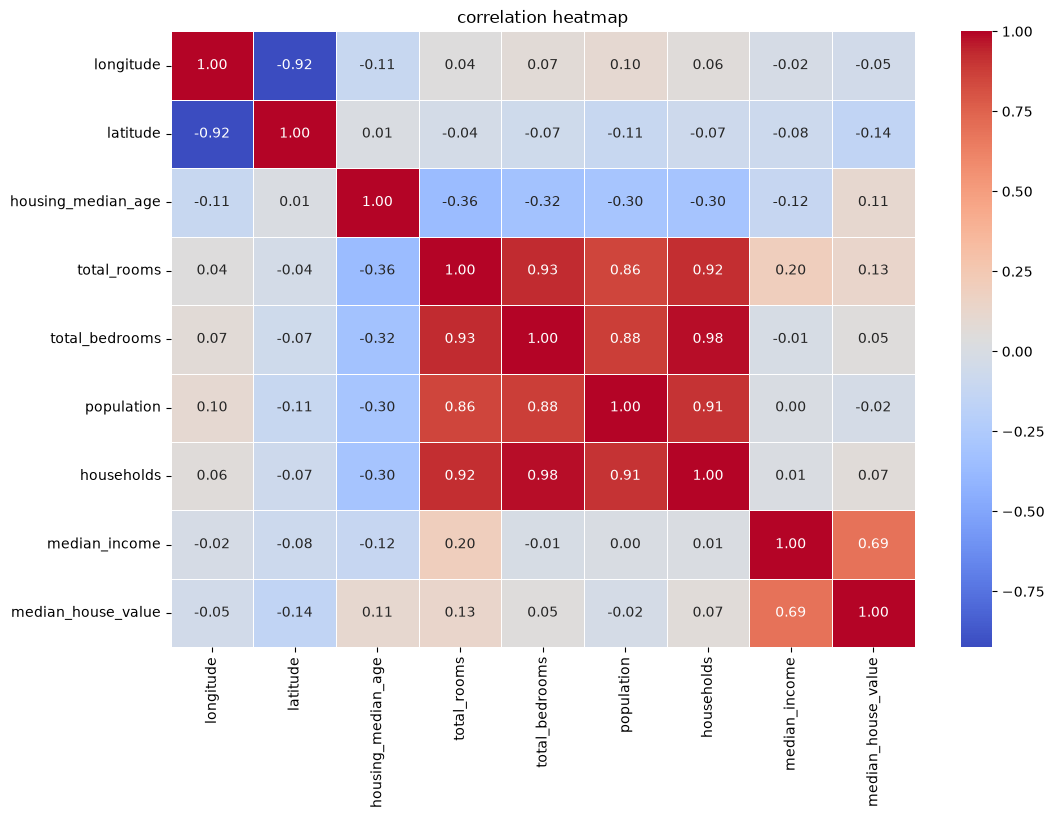

In [20]:
plt.figure(figsize=(12,8))
sns.heatmap(
    correlation,annot=True,cmap="coolwarm",fmt=".2f",linewidths=0.5)
plt.title("correlation heatmap")
plt.show()

In [21]:
print("Ocean Proximity Categories:")
print(df["ocean_proximity"].value_counts())

Ocean Proximity Categories:
ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64


In [22]:
category_analysis = df.groupby("ocean_proximity").agg(
    total_records=("median_house_value", "count"),
    average_price=("median_house_value", "mean"),
    median_price=("median_house_value", "median")
)

print(category_analysis)

                 total_records  average_price  median_price
ocean_proximity                                            
<1H OCEAN                 9136  240084.285464      214850.0
INLAND                    6551  124805.392001      108500.0
ISLAND                       5  380440.000000      414700.0
NEAR BAY                  2290  259212.311790      233800.0
NEAR OCEAN                2658  249433.977427      229450.0


In [23]:
category_analysis = df.groupby("ocean_proximity").agg(
    total_records=("median_house_value", "count"),
    average_price=("median_house_value", "mean"),
    median_price=("median_house_value", "median")
)

print(category_analysis)

                 total_records  average_price  median_price
ocean_proximity                                            
<1H OCEAN                 9136  240084.285464      214850.0
INLAND                    6551  124805.392001      108500.0
ISLAND                       5  380440.000000      414700.0
NEAR BAY                  2290  259212.311790      233800.0
NEAR OCEAN                2658  249433.977427      229450.0


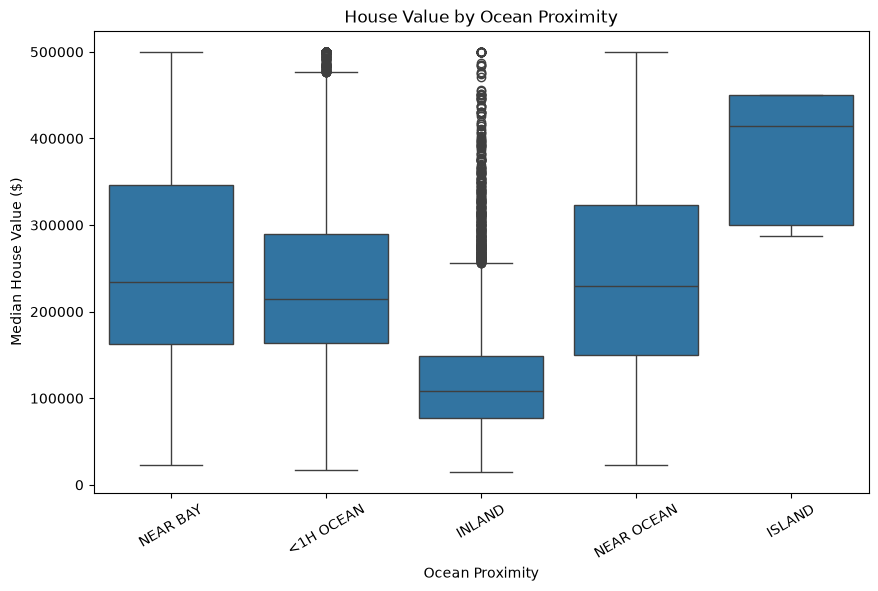

In [24]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="ocean_proximity",
    y="median_house_value"
)

plt.title("House Value by Ocean Proximity")
plt.xlabel("Ocean Proximity")
plt.ylabel("Median House Value ($)")
plt.xticks(rotation=30)

plt.show()

In [25]:
print(category_analysis.round(2))

                 total_records  average_price  median_price
ocean_proximity                                            
<1H OCEAN                 9136      240084.29      214850.0
INLAND                    6551      124805.39      108500.0
ISLAND                       5      380440.00      414700.0
NEAR BAY                  2290      259212.31      233800.0
NEAR OCEAN                2658      249433.98      229450.0


In [26]:
df["rooms_per_household"] = (
    df["total_rooms"] / df["households"]
)

df["bedrooms_per_room"] = (
    df["total_bedrooms"] / df["total_rooms"]
)

df["population_per_household"] = (
    df["population"] / df["households"]
)

df[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
]].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20433.000000,20640.000000
mean,5.429000,0.213039,3.070655
std,2.474173,0.057983,10.386050
min,0.846154,0.100000,0.692308
25%,4.440716,0.175427,2.429741
50%,5.229129,0.203162,2.818116
75%,6.052381,0.239821,3.282261
max,141.909091,1.000000,1243.333333


In [27]:
df[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household"
]].isnull().sum()

rooms_per_household           0
bedrooms_per_room           207
population_per_household      0
dtype: int64

In [28]:
print("Original missing values:")
print(df[[
    "total_bedrooms",
    "bedrooms_per_room"
]].isnull().sum())

print("\nDataset shape:", df.shape)

Original missing values:
total_bedrooms       207
bedrooms_per_room    207
dtype: int64

Dataset shape: (20640, 13)
